# Day 4: Percentiles, Quartiles, IQR & Outlier Detection

## Statistics for Data Analytics and Data Science

### Learning Objectives

- Understand percentiles and quartiles.
- Calculate Q1, Q2 and Q3.
- Understand Interquartile Range (IQR).
- Detect outliers using the IQR method.
- Understand the impact of outliers on business analysis.
- Apply statistical concepts using Python.

**Tools:** Python, NumPy, Pandas, Matplotlib

## 1. Introduction

Percentiles and quartiles help us understand the distribution of data.

They divide an ordered dataset into different parts and help identify the position of values.

IQR (Interquartile Range) measures the spread of the middle 50% of the data.

These concepts are useful for identifying unusual values called outliers.

## 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 3. Create a Sample Dataset

Consider the delivery time (in minutes) of 20 orders.

We will analyze the distribution of delivery times and identify any unusual observations.

In [2]:
# Delivery time data in minutes

data = {
    "delivery_time": [
        18, 20, 21, 22, 23,
        24, 25, 26, 27, 28,
        29, 30, 31, 32, 33,
        34, 35, 36, 38, 90
    ]
}

df = pd.DataFrame(data)

df

,delivery_time
0,18
1,20
2,21
3,22
4,23
5,24
6,25
7,26
8,27
9,28


In [3]:
# Basic dataset information

print("Dataset Shape:", df.shape)

print("\nDescriptive Statistics:")
print(df.describe())

Dataset Shape: (20, 1)

Descriptive Statistics:
       delivery_time
count       20.00000
mean        31.10000
std         14.97331
min         18.00000
25%         23.75000
50%         28.50000
75%         33.25000
max         90.00000


## 4. Percentiles

A percentile indicates the value below which a certain percentage of observations fall.

For example:

- 25th Percentile: Approximately 25% of observations are at or below this value.
- 50th Percentile: 50% of observations are at or below this value.
- 75th Percentile: 75% of observations are at or below this value.
- 90th Percentile: 90% of observations are at or below this value.

Percentiles help us understand the relative position of values within a dataset.

In [4]:
# Calculate selected percentiles

percentiles = np.percentile(
    df["delivery_time"],
    [10, 25, 50, 75, 90]
)

percentile_results = pd.DataFrame({
    "Percentile": ["10th", "25th", "50th", "75th", "90th"],
    "Value": percentiles
})

percentile_results

,Percentile,Value
0,10th,20.90
1,25th,23.75
2,50th,28.50
3,75th,33.25
4,90th,36.20


### Percentile Interpretation

Percentiles help businesses understand the distribution of delivery times.

For example, the 90th percentile represents a delivery time at or below which approximately 90% of observations fall.

This can help businesses monitor delivery performance and identify slower deliveries.

## 5. Quartiles

Quartiles divide an ordered dataset into four equal parts.

There are three main quartiles:

- Q1 (First Quartile): 25th percentile.
- Q2 (Second Quartile): 50th percentile or Median.
- Q3 (Third Quartile): 75th percentile.

Each quartile represents a boundary between parts of the ordered dataset.

In [5]:
# Calculate quartiles

Q1 = df["delivery_time"].quantile(0.25)

Q2 = df["delivery_time"].quantile(0.50)

Q3 = df["delivery_time"].quantile(0.75)

print("Q1:", Q1)
print("Q2:", Q2)
print("Q3:", Q3)

Q1: 23.75
Q2: 28.5
Q3: 33.25


### Quartile Interpretation

- Q1 represents the 25th percentile.
- Q2 represents the median or 50th percentile.
- Q3 represents the 75th percentile.

These values help us understand how delivery times are distributed across the dataset.

## 6. Interquartile Range (IQR)

IQR measures the spread of the middle 50% of observations.

**Formula:**

IQR = Q3 - Q1

IQR is less affected by extreme values than Range because it focuses on the middle 50% of the data.

It is commonly used for detecting outliers.

In [6]:
# Calculate Interquartile Range

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 23.75
Q3: 33.25
IQR: 9.5


## 7. Outlier Detection Using IQR

An outlier is an observation that is unusually far from the other values in a dataset.

The IQR method uses lower and upper boundaries to identify potential outliers.

**Lower Bound:**

Q1 - 1.5 × IQR

**Upper Bound:**

Q3 + 1.5 × IQR

Values below the lower bound or above the upper bound are identified as potential outliers.

**Important:** An outlier is not automatically an error. It should be investigated before removing it.

In [7]:
# Calculate lower and upper bounds

lower_bound = Q1 - (1.5 * IQR)

upper_bound = Q3 + (1.5 * IQR)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: 9.5
Upper Bound: 47.5


In [8]:
# Identify potential outliers

outliers = df[
    (df["delivery_time"] < lower_bound) |
    (df["delivery_time"] > upper_bound)
]

outliers

,delivery_time
19,90


### Outlier Interpretation

The IQR method identifies observations outside the lower and upper boundaries.

In this dataset, the delivery time of 90 minutes is identified as a potential outlier.

This unusually high delivery time may indicate:

- Delivery delays.
- Operational issues.
- Unexpected circumstances.
- Incorrect data entry.

Further investigation is required before deciding whether to remove or retain the observation.

## 8. Visualizing Outliers Using a Box Plot

A box plot visually represents:

- Minimum value (excluding outliers).
- First Quartile (Q1).
- Median (Q2).
- Third Quartile (Q3).
- Maximum value (excluding outliers).
- Potential outliers.

The box represents the middle 50% of the data.

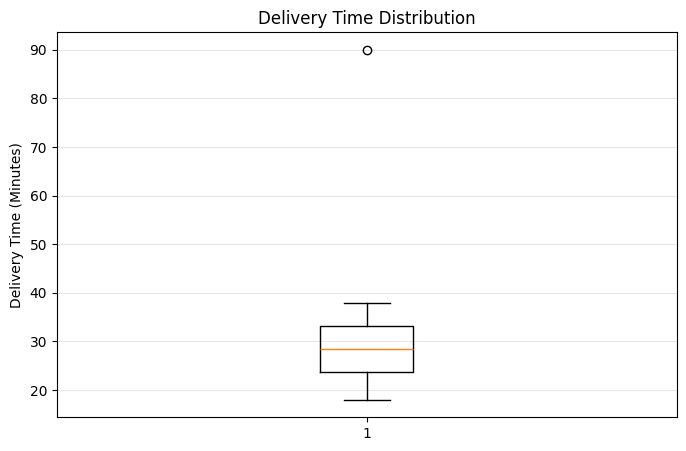

In [9]:
# Create a box plot

plt.figure(figsize=(8, 5))

plt.boxplot(df["delivery_time"])

plt.title("Delivery Time Distribution")
plt.ylabel("Delivery Time (Minutes)")
plt.grid(axis="y", alpha=0.3)

plt.show()

### Box Plot Interpretation

The box plot helps identify the spread of delivery times and potential outliers.

The observation at 90 minutes appears separately from the main distribution.

Box plots are useful for comparing distributions and detecting unusual observations.

## 9. Impact of Outliers on Mean and Median

Outliers can significantly affect the mean.

The median is generally more resistant to extreme values.

Let's compare the mean and median before and after excluding the identified outlier.

In [10]:
# Calculate mean and median with the outlier

mean_with_outlier = df["delivery_time"].mean()

median_with_outlier = df["delivery_time"].median()

# Remove identified outliers for comparison

df_without_outliers = df[
    (df["delivery_time"] >= lower_bound) &
    (df["delivery_time"] <= upper_bound)
]

mean_without_outlier = df_without_outliers["delivery_time"].mean()

median_without_outlier = df_without_outliers["delivery_time"].median()

# Compare results

comparison = pd.DataFrame({
    "With Outlier": [mean_with_outlier, median_with_outlier],
    "Without Outlier": [mean_without_outlier, median_without_outlier]
}, index=["Mean", "Median"])

comparison

,With Outlier,Without Outlier
Mean,31.1,28.0
Median,28.5,28.0


### Business Interpretation

The extreme delivery time increases the mean more than the median.

This demonstrates that:

- Mean is sensitive to extreme values.
- Median is more resistant to extreme values.
- The appropriate measure depends on the business problem and data distribution.

**Important:** Removing outliers should not be automatic. Business context and data quality must be considered before removal.

## 10. Business Applications

Percentiles, quartiles and IQR are useful in several business scenarios.

### E-commerce
- Analyzing delivery time distribution.
- Identifying unusually delayed orders.
- Understanding customer spending patterns.

### Banking and Finance
- Identifying unusual transaction amounts.
- Analyzing income and loan distributions.
- Detecting extreme financial observations.

### Human Resources
- Understanding employee salary distribution.
- Comparing salary ranges across departments.

### Operations
- Monitoring process variability.
- Identifying unusual production or delivery times.

## 11. Key Differences

| Concept | Meaning |
|---|---|
| Percentile | Indicates the position of a value in a dataset |
| Quartiles | Divide ordered data into four parts |
| Q1 | 25th percentile |
| Q2 | 50th percentile or Median |
| Q3 | 75th percentile |
| IQR | Difference between Q3 and Q1 |
| Outlier | An unusually distant observation |

### Important Points

- Percentiles help understand data distribution.
- Quartiles divide data into four parts.
- IQR measures the spread of the middle 50%.
- The IQR method helps identify potential outliers.
- Outliers should be investigated before removal.

## 12. Interview Questions

### Q1. What is a percentile?
A percentile indicates the value below which a specified percentage of observations fall.

### Q2. What are quartiles?
Quartiles divide an ordered dataset into four equal parts.

### Q3. What is the relationship between Q2 and Median?
Q2 is the 50th percentile and represents the median.

### Q4. What is IQR?
IQR is the difference between the third quartile and first quartile.

### Q5. How do you detect outliers using IQR?
Calculate the lower and upper bounds using Q1 - 1.5 × IQR and Q3 + 1.5 × IQR. Values outside these bounds are potential outliers.

### Q6. Why is IQR preferred over Range for identifying the spread of the middle data?
IQR focuses on the middle 50% of observations and is less affected by extreme values.

### Q7. Should all outliers be removed?
No. Outliers should be investigated based on data quality and business context before removal.

## 13. Practice Tasks

1. Create a dataset containing the monthly purchase amounts of 20 customers.
2. Calculate the 25th, 50th and 75th percentiles.
3. Calculate Q1, Q2 and Q3.
4. Calculate the IQR.
5. Identify potential outliers using the IQR method.
6. Visualize the data using a box plot.
7. Compare the mean and median before and after excluding potential outliers.
8. Explain your findings from a business perspective.

## Conclusion

In this notebook, we learned how to use percentiles, quartiles and IQR to understand data distribution and identify potential outliers.

We also explored how extreme observations can affect statistical measures such as mean and median.

These concepts are important for data cleaning, exploratory data analysis and business decision-making.

**Next Topic:** Skewness, Kurtosis and Data Distribution.